In [1]:
import os
import sys
import tempfile
from pathlib import Path
from IPython.display import Image, display

# The notebook starts in docs/examples. Keep generated files outside the checkout.
repository = Path.cwd().parents[1]
workspace = tempfile.TemporaryDirectory(prefix="croak-gallery-")
(Path(workspace.name) / "examples").symlink_to(repository / "examples", target_is_directory=True)
sys.path.insert(0, str(repository / "examples"))
os.chdir(workspace.name)

In [2]:
"""Compare two retrieval models for a bundled simulated RDW trace.

Both the hollow-capillary source and TG-FROG instrument are simulated. The
legacy reduced dataset contains a 2 mm collection window; this example selects
9.5 micrometres of fused silica. It uses defringing, an empirical spectral
correction and the integrated beamlet reference. The extended fit also frees
the delay offset and smearing scale. These choices differ from the revised
draft protocol; the plotted native fields are not its common on-axis comparison.

Run ``uv run python examples/example_paper_rdw.py`` from the repository root.
The seeded calculations print residuals and durations and write ``paper_rdw.png``.
Inspect pulse shape and spectrum together: a small residual does not certify
field accuracy, and a fitted kernel can absorb other discrepancies.
"""

from __future__ import annotations

import matplotlib
import numpy as np

matplotlib.use("Agg")

import matplotlib.pyplot as plt  # noqa: E402 - must follow matplotlib.use above

import croak  # noqa: E402 - imports pyplot transitively
from croak.session import (  # noqa: E402 - see note above
    PreprocParams,
    RetrieveParams,
    SimulatedLoadParams,
    assemble_simulated_load_data,
    build_tracedata,
    run_retrieval,
)

DATA = "examples/data/tgfrog_sim_rdw_duv.h5"
Z_UM = 9.5
TRUE_FWHM_FS = 1.06

# The illustrative band for this scan (the RDW spectrum reaches further to the red
# than the Gaussian test pulse), with the delay crop at the scan's uniform core.
PREPROC = PreprocParams(
    lam_min_nm=148.0,
    lam_max_nm=830.0,
    lam_bound_min_nm=74.0,
    lam_bound_max_nm=1245.0,
    trange_fs=150.0,
    tau_min_fs=-38.0,
    tau_max_fs=38.0,
    lamm_min_nm=148.0,
    lamm_max_nm=830.0,
    lamm_bound_min_nm=148.0,
    lamm_bound_max_nm=830.0,
    taum_min_fs=-38.0,
    taum_max_fs=38.0,
    tau_bound_min_fs=-38.0,
    tau_bound_max_fs=38.0,
    defringe=True,
)


def main() -> None:
    """Retrieve with both models and plot the comparison against the truth."""
    sim = SimulatedLoadParams(
        frog_path=DATA,
        z_thickness_um=Z_UM,
        lam_min_nm=148.0,
        lam_max_nm=830.0,
        third_order=True,
        third_order_exp=4.0,
        use_spectrum=True,
        spectrum_source="beamlet",
    )
    data = assemble_simulated_load_data(sim)
    td = build_tracedata(PREPROC, data)
    truth = data["truth"]

    extended = RetrieveParams(
        solver="warm-lbfgs",
        maxiters=300,
        dispersive=True,
        material="SiO2",
        thickness_um=Z_UM,
        npoints=10,
        smearing=True,
        smear_hole_diameter_mm=1.0,
        smear_hole_spacing_mm=1.0,
        fit_smearing=True,  # the kernel scale is fitted from the data
        fit_tau0=True,
    )
    standard = RetrieveParams(solver="warm-lbfgs", maxiters=300)

    out = {}
    for label, rp in (("extended (fitted kernel)", extended), ("standard", standard)):
        res = run_retrieval(rp, td, rng=np.random.default_rng(0))
        pr = croak.process_result(res, measured=td.trace)
        out[label] = pr
        print(
            f"{label:24s}  R = {100 * res.error:.3f}%  "
            f"FWHM = {pr.fwhm_retr * 1e15:.2f} fs  (truth {TRUE_FWHM_FS} fs)"
        )

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")

    ax1.fill_between(
        truth.t * 1e15, truth.It, color="0.8", label="stored beamlet reference"
    )
    for label, style in zip(out, ("-", "--"), strict=True):
        pr = out[label]
        t0 = pr.t_over[pr.It_retr.argmax()]
        ax1.plot((pr.t_over - t0) * 1e15, pr.It_retr, style, label=label)
    ax1.set_xlim(-6, 12)
    ax1.set_xlabel("time (fs)")
    ax1.set_ylabel("intensity (norm.)")
    ax1.legend()

    if truth.lam is not None:
        ax2.fill_between(truth.lam * 1e9, truth.Iw, color="0.8", label="true spectrum")
    for label, style in zip(out, ("-", "--"), strict=True):
        pr = out[label]
        ax2.plot(pr.wavelength * 1e9, pr.Ilam, style, label=label)
    ax2.set_xlim(200, 340)
    ax2.set_xlabel("wavelength (nm)")
    ax2.set_ylabel("spectral intensity (norm.)")
    ax2.legend()

    fig.savefig("paper_rdw.png", dpi=150)
    print("wrote paper_rdw.png")


if __name__ == "__main__":
    main()


extended (fitted kernel)  R = 0.049%  FWHM = 1.17 fs  (truth 1.06 fs)


standard                  R = 0.246%  FWHM = 2.64 fs  (truth 1.06 fs)
wrote paper_rdw.png


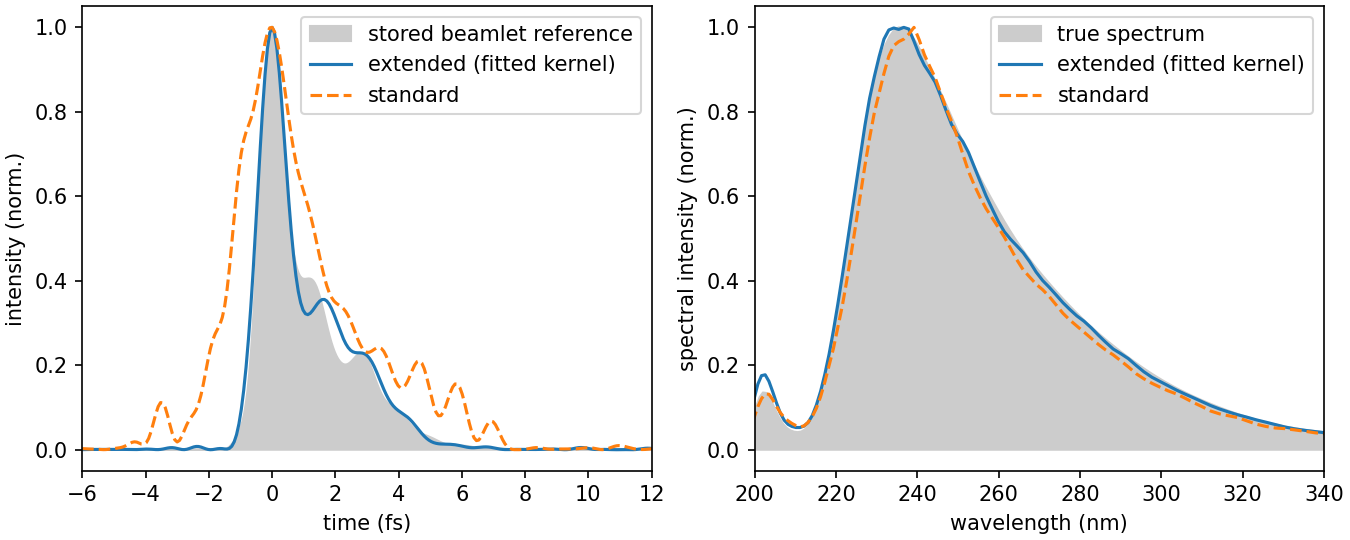

In [3]:
display(Image(filename="paper_rdw.png"))